# EDA: SMS Spam Collection and Enron-Spam

**ECS 171 - Does Naive Bayes Really Learn in O(log n)?** (Andrew Ngo, Kevin Liu, Bryce Lee)

Data:
* `SMSSpamCollection.csv` - UCI SMS Spam Collection
* `enron_spam_data.csv` - Enron-Spam (Metsis et al., 2006), combined-CSV of all six folders.

Colours: **blue = ham, orange = spam** in every figure; each corpus gets its own panel.

In [1]:
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

DATA = Path("data/raw")
HAM, SPAM = "#2a78d6", "#eb6834"          # categorical slots 1-2 (validated colour-blind safe)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "lines.linewidth": 2,
})
CORPORA = ["SMS Spam", "Enron-Spam"]
thousands = FuncFormatter(lambda v, _p: f"{v:,.0f}")

## 1. Load Data

In [2]:
def load_sms():
    path = next(p for p in (DATA / "SMSSpamCollection", DATA / "SMSSpamCollection.csv") if p.exists())
    rows = [line.split("\t", 1) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]
    df = pd.DataFrame(rows, columns=["label", "text"])
    assert set(df.label) == {"ham", "spam"}
    return df.assign(spam=(df.label == "spam").astype(int))

def load_enron():
    df = pd.read_csv(DATA / "enron_spam_data.csv")
    assert set(df["Spam/Ham"]) == {"ham", "spam"}
    text = df["Subject"].fillna("") + "\n" + df["Message"].fillna("")
    return pd.DataFrame({"label": df["Spam/Ham"], "text": text, "spam": (df["Spam/Ham"] == "spam").astype(int),
                         "date": pd.to_datetime(df["Date"], errors="coerce"),
                         "no_subject": df["Subject"].isna(), "no_body": df["Message"].isna()})

raw = {"SMS Spam": load_sms(), "Enron-Spam": load_enron()}
for name, df in raw.items():
    print(f"{name:11s} {len(df):6,} messages   spam {df.spam.sum():6,} ({df.spam.mean():.1%})")
print()
print("Enron rows with no subject:", raw["Enron-Spam"].no_subject.sum(),
      "  no body:", raw["Enron-Spam"].no_body.sum())
print("\nSMS examples:")
for lab in ("ham", "spam"):
    for t in raw["SMS Spam"].query("label == @lab").text.head(2):
        print(f"  [{lab}] {t[:110]}")

SMS Spam     5,574 messages   spam    747 (13.4%)
Enron-Spam  33,716 messages   spam 17,171 (50.9%)

Enron rows with no subject: 289   no body: 371

SMS examples:
  [ham] Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..
  [ham] Ok lar... Joking wif u oni...
  [spam] Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question
  [spam] FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb o


## 2. Duplicates

A duplicate is the same text after lower-casing and collapsing whitespace. With random train/test splits, any duplicated messages can land on both sides and artificially inflate test accuracy.

SMS Spam: 415 extra copies; 0 texts carry both labels
Enron-Spam: 3,578 extra copies; 0 texts carry both labels

    corpus class  messages  extra copies share
  SMS Spam   ham      4827           310  6.4%
  SMS Spam  spam       747           105 14.1%
Enron-Spam   ham     16545           955  5.8%
Enron-Spam  spam     17171          2623 15.3%


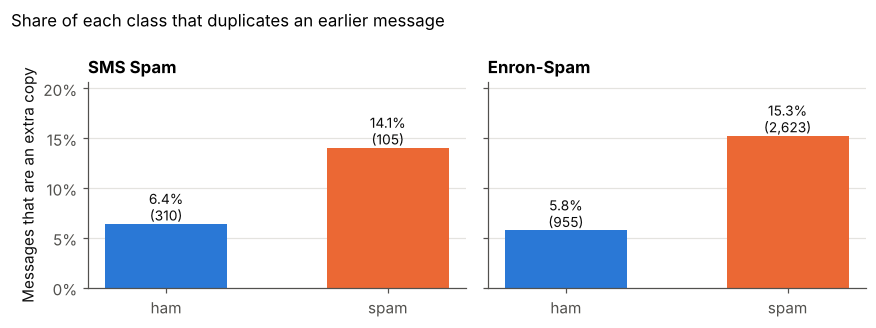

In [3]:
def norm_key(t):
    return " ".join(t.lower().split())

dup_rows = []
for name, df in raw.items():
    key = df.text.map(norm_key)
    is_copy = key.duplicated()                       # every occurrence after the first
    conflicting = (pd.DataFrame({"k": key, "s": df.spam}).groupby("k").s.nunique() > 1).sum()
    for cls, lab in ((0, "ham"), (1, "spam")):
        n_cls = (df.spam == cls).sum()
        n_copy = (is_copy & (df.spam == cls)).sum()
        dup_rows.append({"corpus": name, "class": lab, "messages": n_cls, "extra copies": n_copy,
                         "share": n_copy / n_cls})
    raw[name] = df.assign(key=key, is_copy=is_copy)
    print(f"{name}: {is_copy.sum():,} extra copies; {conflicting} texts carry both labels")
dups = pd.DataFrame(dup_rows)
print(); print(dups.to_string(index=False, formatters={"share": "{:.1%}".format}))

fig, axes = plt.subplots(1, 2, figsize=(8, 3.0), sharey=True)
for ax, name in zip(axes, CORPORA):
    d = dups[dups.corpus == name]
    bars = ax.bar(d["class"], d.share, color=[HAM, SPAM], width=0.55)
    for b, (_, r) in zip(bars, d.iterrows()):
        ax.text(b.get_x() + b.get_width() / 2, r.share, f"{r.share:.1%}\n({r['extra copies']:,})",
                ha="center", va="bottom", fontsize=9, color=INK)
    ax.set_title(name)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Messages that are an extra copy")
axes[0].set_ylim(0, dups.share.max() * 1.35)
fig.suptitle("Share of each class that duplicates an earlier message", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

**Findings:** Both datasets contain exact duplicates: 415 extra copies in SMS (7.4% of messages) and 3,578 in Enron (10.6%). Spam is duplicated about twice as often as ham in both datasets (14.1% vs. 6.4% in SMS; 15.3% vs. 5.8% in Enron), as one would expect from spam campaigns that send the same text many times. Duplicated text never has two different labels, so we can safely drop them. If we kept them, the same message could appear in both a training set and its test set, and spam would be the class that benefits most.

We will remove exact duplicates before any split.


In [ ]:
data = {name: df[~df.is_copy].reset_index(drop=True) for name, df in raw.items()}
TOKEN_RE = re.compile(r"[a-z0-9]+|[£$€!]")     # tokenizer we will use
for name, df in data.items():
    df["tokens"] = df.text.map(lambda t: TOKEN_RE.findall(t.lower()))
    df["n_tokens"] = df.tokens.map(len)
    print(f"{name:11s} {len(df):6,} unique messages   spam {df.spam.sum():6,} ({df.spam.mean():.1%})")

SMS Spam     5,159 unique messages   spam    642 (12.4%)
Enron-Spam  30,138 unique messages   spam 14,548 (48.3%)


## 3. Class balance

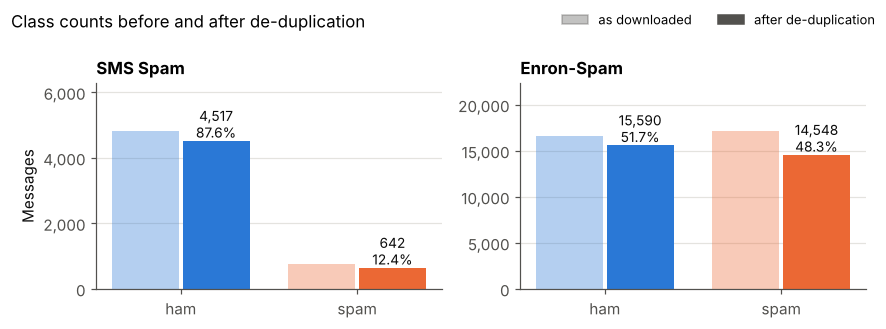

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.0))
for ax, name in zip(axes, CORPORA):
    before = raw[name].spam.value_counts().reindex([0, 1])
    after = data[name].spam.value_counts().reindex([0, 1])
    x = np.arange(2)
    ax.bar(x - 0.2, before, 0.38, color=[HAM, SPAM], alpha=0.35, label="as downloaded")
    ax.bar(x + 0.2, after, 0.38, color=[HAM, SPAM], label="after de-duplication")
    for xi, v in zip(x + 0.2, after):
        ax.text(xi, v, f"{v:,}\n{v / after.sum():.1%}", ha="center", va="bottom", fontsize=9, color=INK)
    ax.set_xticks(x, ["ham", "spam"])
    ax.set_title(name)
    ax.yaxis.set_major_formatter(thousands)
    ax.set_ylim(0, before.max() * 1.3)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Messages")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=MUTED, alpha=0.35, label="as downloaded"), Patch(color=MUTED, label="after de-duplication")],
           loc="upper right", ncols=2, fontsize=8.5)
fig.suptitle("Class counts before and after de-duplication", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

**Findings:** After removing duplicates, SMS has 5,159 messages, of which only 642 (12.4%) are spam. Enron has 30,138, nearly balanced at 48.3% spam. Because spam is duplicated more, removing duplicates lowers the spam share in both datasets (SMS 13.4% to 12.4%; Enron 50.9% to 48.3%). On SMS, always predicting ham already gives 12.4% error, the baseline any classifier must beat. The imbalance matters most at small training sizes: a stratified SMS training set of m = 64 holds only about 8 spam messages, and an unstratified set of m = 8 has about a one-in-three chance of containing no spam at all.

We will stratify all splits and force at least one example of each class into every training set.

## 4. Message length and surface cues

SMS Spam token-count quantiles (10/50/90%):
      0.1  0.5  0.9
ham     5   11   29
spam   16   28   33

Enron-Spam token-count quantiles (10/50/90%):
      0.1  0.5  0.9
ham    27  131  494
spam   31  106  515


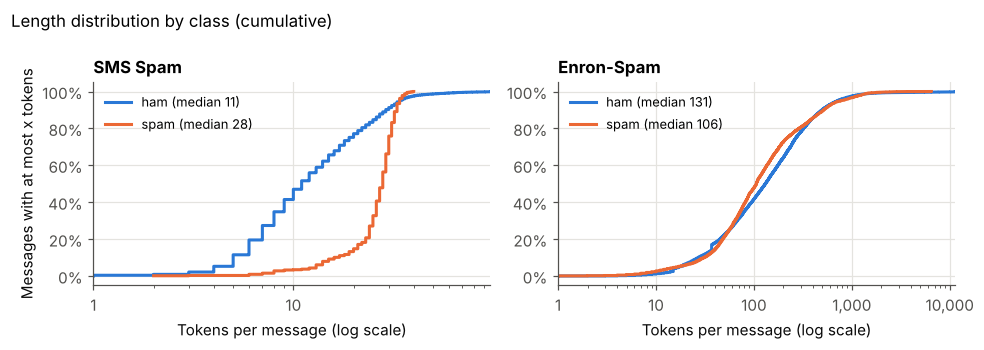

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, name in zip(axes, CORPORA):
    df = data[name]
    for cls, col, lab in ((0, HAM, "ham"), (1, SPAM, "spam")):
        v = np.sort(df.n_tokens[df.spam == cls].clip(lower=1).to_numpy())
        ax.step(v, np.arange(1, len(v) + 1) / len(v), where="post", color=col, linewidth=2,
                label=f"{lab} (median {int(np.median(v))})")
    ax.set_xscale("log")
    ax.set_xlim(1, df.n_tokens.quantile(0.999))
    ax.xaxis.set_major_formatter(thousands)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_title(name)
    ax.set_xlabel("Tokens per message (log scale)")
    ax.legend(fontsize=8.5, loc="upper left")
axes[0].set_ylabel("Messages with at most x tokens")
fig.suptitle("Length distribution by class (cumulative)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

for name, df in data.items():
    q = df.groupby("spam").n_tokens.quantile([0.1, 0.5, 0.9]).unstack()
    q.index = ["ham", "spam"]
    print(name, "token-count quantiles (10/50/90%):"); print(q.round(0).astype(int).to_string()); print()

**Findings:** On SMS, length separates the classes: spam is longer (median 28 tokens vs. 11 for ham) and bunched between about 20 and 35 tokens. That fits single 160-character marketing texts written to the limit, while ham has a long tail of very short replies. On Enron the two curves almost coincide (median 131 tokens for ham, 106 for spam), so length carries little signal there. Our models will instead see binary word presence, not length. Longer messages switch on more features, so on SMS the spam class will tend to have more active features per message.


class                           ham   spam
corpus     cue                            
Enron-Spam 5+ digit number    0.261  0.175
           URL (http / www.)  0.076  0.306
           contains !         0.171  0.542
           contains $         0.138  0.284
           contains £         0.000  0.005
SMS Spam   5+ digit number    0.001  0.765
           URL (http / www.)  0.000  0.136
           contains !         0.117  0.470
           contains $         0.003  0.006
           contains £         0.001  0.327

SMS tokens our tokenizer keeps but CountVectorizer's default pattern drops (top 12):
  'i':2849, 'a':1301, '!':1247, 'u':1075, 's':554, '2':490, 't':456, 'm':419, '4':289, '£':268, 'r':145, '1':144


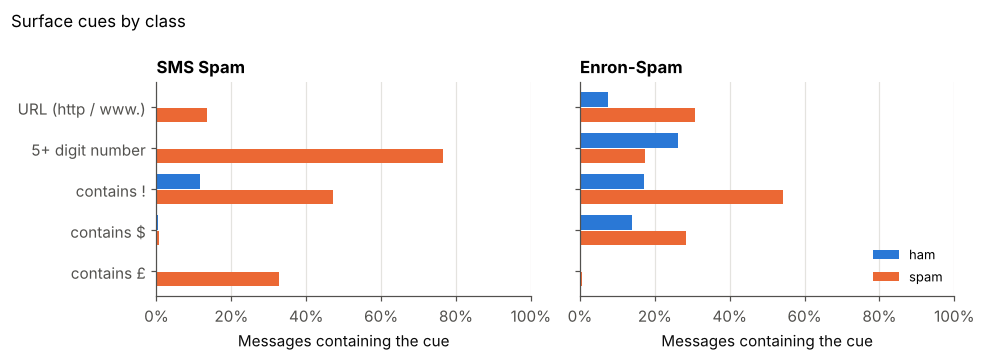

In [ ]:
CUES = {"contains £": "£", "contains $": r"\$", "contains !": "!",
        "5+ digit number": r"\d{5,}", "URL (http / www.)": r"http|www\."}
cue_rows = []
for name, df in data.items():
    for cue, pat in CUES.items():
        hit = df.text.str.contains(pat, regex=True)
        for cls, lab in ((0, "ham"), (1, "spam")):
            cue_rows.append({"corpus": name, "cue": cue, "class": lab, "share": hit[df.spam == cls].mean()})
cues = pd.DataFrame(cue_rows)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), sharey=True)
y = np.arange(len(CUES))
for ax, name in zip(axes, CORPORA):
    c = cues[cues.corpus == name].pivot(index="cue", columns="class", values="share").reindex(list(CUES))
    ax.barh(y + 0.19, c["ham"], 0.36, color=HAM, label="ham")
    ax.barh(y - 0.19, c["spam"], 0.36, color=SPAM, label="spam")
    ax.set_yticks(y, list(CUES))
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlim(0, 1)
    ax.set_title(name)
    ax.set_xlabel("Messages containing the cue")
    ax.grid(axis="y", visible=False)
axes[1].legend(loc="lower right", fontsize=8.5)
fig.suptitle("Surface cues by class", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()
print(cues.pivot_table(index=["corpus", "cue"], columns="class", values="share").round(3).to_string())

default_tok = re.compile(r"(?u)\b\w\w+\b")
sms = data["SMS Spam"]
lost = Counter(t for ts in sms.tokens for t in ts if not default_tok.fullmatch(t))
print("\nSMS tokens our tokenizer keeps but CountVectorizer's default pattern drops (top 12):")
print("  " + ", ".join(f"{t!r}:{c}" for t, c in lost.most_common(12)))

**Findings:** SMS spam has strong surface markers. 77% of spam contains a number of five or more digits (phone numbers and short codes), against 0.1% of ham. 33% contains "£", 47% contains "!", and 14% contains a URL, against 0.1%, 12% and 0% of ham. "\$" is irrelevant, as the dataset is British. On Enron the same cues are much weaker and one is reversed: long digit runs are more common in ham (26\% vs. 18\%), from phone numbers and dates in corporate mail. scikit-learn's default token pattern keeps only words of two or more characters, so it will drop "i", "!", "u", "2", "4" and "£", some of the most frequent and most label-related SMS tokens.

We will tokenize with `[a-z, 0-9]+|[£$€!]` after lower-casing.

## 5. Features

Our experiment varies the vocabulary size n. The vocabulary will be ranked on a held-out dev split (tentatively 20%, stratified) that is never used for training or testing, so the dev split's vocabulary caps n.

SMS Spam: 8,748 distinct tokens overall; dev split 1,031 msgs has 3,362
Enron-Spam: 157,318 distinct tokens overall; dev split 6,028 msgs has 65,469


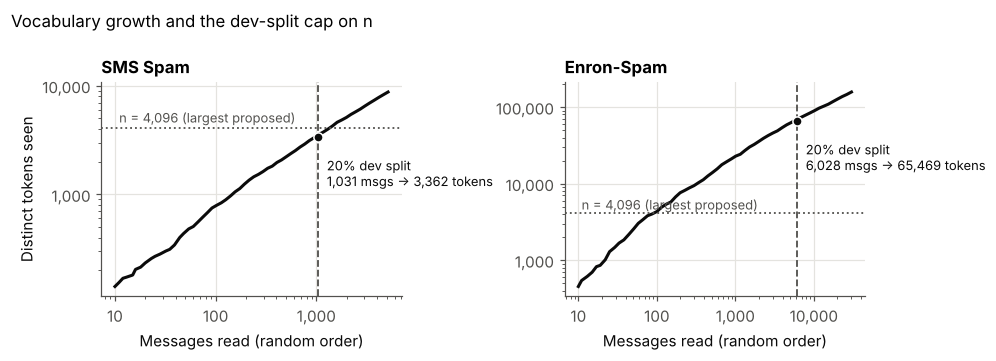

In [8]:
DEV_FRAC, SEED = 0.2, 171

def dev_split(y, frac=DEV_FRAC, seed=SEED):
    rng = np.random.default_rng(seed)
    dev = np.concatenate([rng.permutation(np.flatnonzero(y == c))[: round(frac * (y == c).sum())] for c in (0, 1)])
    return np.sort(dev), np.setdiff1d(np.arange(len(y)), dev)

doc_freq, dev_idx, pool_idx = {}, {}, {}
for name, df in data.items():
    doc_freq[name] = Counter(t for ts in df.tokens for t in set(ts))
    dev_idx[name], pool_idx[name] = dev_split(df.spam.to_numpy())

fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for ax, name in zip(axes, CORPORA):
    df = data[name]
    order = np.random.default_rng(0).permutation(len(df))
    seen, growth = set(), []
    checkpoints = np.unique(np.logspace(1, np.log10(len(df)), 60).astype(int))
    j = 0
    for i, idx in enumerate(order, 1):
        seen.update(df.tokens.iat[idx])
        if j < len(checkpoints) and i == checkpoints[j]:
            growth.append((i, len(seen))); j += 1
    g = np.array(growth)
    ax.plot(g[:, 0], g[:, 1], color=INK, linewidth=2)
    n_dev = len(dev_idx[name])
    dev_vocab = len({t for i in dev_idx[name] for t in df.tokens.iat[i]})
    ax.axvline(n_dev, color=MUTED, linestyle="--", linewidth=1.2)
    ax.axhline(4096, color=MUTED, linestyle=":", linewidth=1.2)
    ax.annotate(f"20% dev split\n{n_dev:,} msgs -> {dev_vocab:,} tokens", (n_dev, dev_vocab),
                xytext=(6, -32), textcoords="offset points", fontsize=8.5, color=INK)
    ax.text(g[0, 0] * 1.1, 4096 * 1.12, "n = 4,096 (largest proposed)", fontsize=8.5, color=MUTED)
    ax.plot([n_dev], [dev_vocab], "o", color=INK, markersize=6, markeredgecolor="white")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.xaxis.set_major_formatter(thousands); ax.yaxis.set_major_formatter(thousands)
    ax.set_title(name)
    ax.set_xlabel("Messages read (random order)")
    print(f"{name}: {len(doc_freq[name]):,} distinct tokens overall; dev split {n_dev:,} msgs has {dev_vocab:,}")
axes[0].set_ylabel("Distinct tokens seen")
fig.suptitle("Vocabulary growth and the dev-split cap on n", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

**Findings:** Every additional message keeps adding new tokens, so the number of available features depends on how many messages we rank them on. The 20% dev split (1,031 SMS messages) contains only 3,362 distinct tokens, below the largest vocabulary of n = 4,096 (from our proposal). The Enron dev split (6,028 emails) contains 65,469, more than needed.

n = 2,048 and run Enron up to n = 4,096. We do not grow the SMS dev split instead, because every message moved into it is lost from the training pool (which is already small).

SMS Spam: 56% of distinct tokens occur in exactly one message
Enron-Spam: 54% of distinct tokens occur in exactly one message


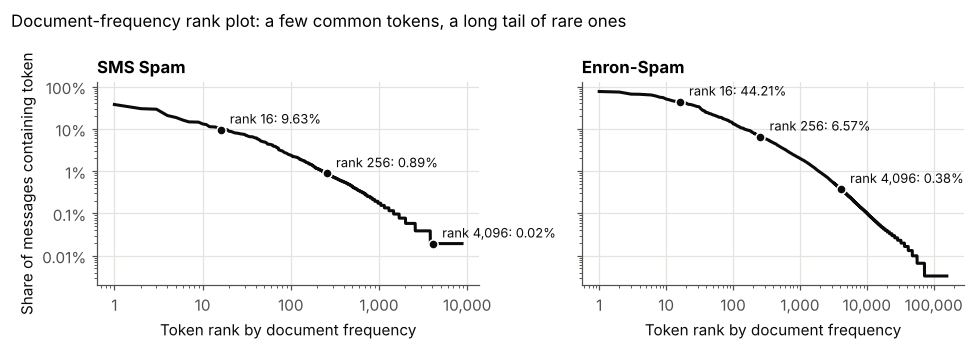

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, name in zip(axes, CORPORA):
    df_counts = np.sort(np.array(list(doc_freq[name].values())))[::-1]
    share = df_counts / len(data[name])
    ax.plot(np.arange(1, len(share) + 1), share, color=INK, linewidth=2)
    for n in (16, 256, 4096):
        if n <= len(share):
            ax.plot([n], [share[n - 1]], "o", color=INK, markersize=6, markeredgecolor="white")
            ax.annotate(f"rank {n:,}: {share[n - 1]:.2%}", (n, share[n - 1]), xytext=(6, 4),
                        textcoords="offset points", fontsize=8.5, color=INK)
    once = (df_counts == 1).mean()
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.xaxis.set_major_formatter(thousands)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _p: f"{v * 100:g}%"))
    ax.set_title(name)
    ax.set_xlabel("Token rank by document frequency")
    print(f"{name}: {once:.0%} of distinct tokens occur in exactly one message")
axes[0].set_ylabel("Share of messages containing token")
fig.suptitle("Document-frequency rank plot: a few common tokens, a long tail of rare ones", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

**Findings:** Both databases follow the usual long-tailed pattern: a handful of tokens appear in a large share of messages, and more than half of all distinct tokens (56% in SMS, 54% in Enron) appear in exactly one message. The tail is much thinner for SMS. Its 4,096th most common token appears in 0.02% of messages (about one message), against 0.38% (about 115 emails) for Enron's. So in SMS, the features added at the top of the n grid will each be seen only a few times in the whole database, let alone in a small training set.


## 6. Token information

Tokens are ranked by mutual information (MI) between "token present" and the label, computed on the
dev split only. This is the ranking that will define the top-n vocabularies.

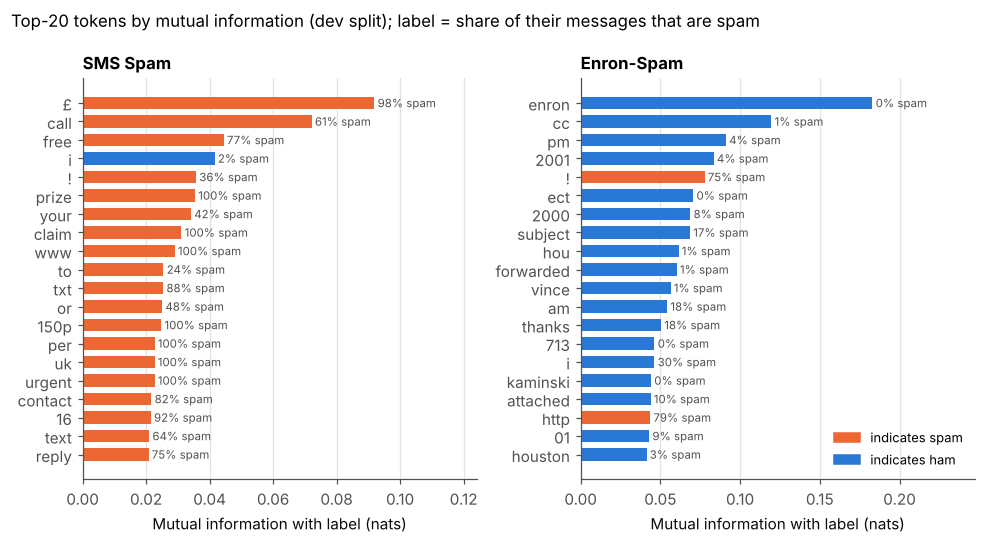

In [10]:
def mi_rank(token_lists, y):
    y = np.asarray(y); N, N1 = len(y), int(y.sum())
    df_all, df_spam = Counter(), Counter()
    for toks, lab in zip(token_lists, y):
        s = set(toks); df_all.update(s)
        if lab: df_spam.update(s)
    p_y = np.array([N - N1, N1]) / N
    out = []
    for tok, d in df_all.items():
        s = df_spam[tok]
        joint = np.array([[N - N1 - (d - s), N1 - s], [d - s, s]]) / N
        p_x = joint.sum(axis=1, keepdims=True)
        with np.errstate(divide="ignore", invalid="ignore"):
            mi = np.nansum(joint * np.log(joint / (p_x * p_y)))
        spam_rate = s / d
        out.append((tok, mi, d, spam_rate))
    out.sort(key=lambda r: (-r[1], -r[2], r[0]))
    return pd.DataFrame(out, columns=["token", "mi", "dev_df", "spam_rate"])

ranked = {}
for name, df in data.items():
    dev = df.iloc[dev_idx[name]]
    ranked[name] = mi_rank(dev.tokens, dev.spam)

fig, axes = plt.subplots(1, 2, figsize=(9, 5.0))
for ax, name in zip(axes, CORPORA):
    r = ranked[name].head(20).iloc[::-1]
    base_rate = data[name].spam.mean()
    cols = [SPAM if s > base_rate else HAM for s in r.spam_rate]
    ax.barh(r.token, r.mi, color=cols, height=0.7)
    for yv, (_, row) in enumerate(r.iterrows()):
        ax.text(row.mi, yv, f" {row.spam_rate:.0%} spam", va="center", fontsize=7.5, color=MUTED)
    ax.set_title(name)
    ax.set_xlabel("Mutual information with label (nats)")
    ax.set_xlim(0, r.mi.max() * 1.35)
    ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color=SPAM, label="indicates spam"), Patch(color=HAM, label="indicates ham")],
               loc="lower right", fontsize=8.5)
fig.suptitle("Top-20 tokens by mutual information (dev split); label = share of their messages that are spam",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

**Findings:** On SMS, almost every top-ranked token signals spam. These are marketing words and units ("£", "call", "free", "prize", "claim", "www", "txt", "150p", "urgent"), many appearing only in spam. The one strong ham signal is "i". Ham on SMS is mostly recognized by the absence of spam words. Enron is the opposite: the top tokens are overwhelmingly ham signals, and most are artifacts of where the ham came from. They include the company name ("enron"), mail-header words ("cc", "pm", "forwarded", "subject"), Enron's Houston office ("ect", "hou", "houston", area code "713"), one mailbox owner ("vince", "kaminski"), and years ("2000", "2001"). Only "!" and "http" signal spam. The MI ranking is working as intended, but on Enron it rewards source identification as much as spam detection.


            ham   spam
token                 
enron     0.442  0.000
vince     0.173  0.002
kaminski  0.120  0.000
ect       0.199  0.001
hou       0.184  0.002
2000      0.269  0.024
2001      0.268  0.010
2004      0.003  0.081
2005      0.002  0.090

Date range by class:
            min     median        max
spam                                 
ham  1999-12-10 2001-03-01 2002-03-25
spam 2001-05-25 2005-01-30 2005-09-06


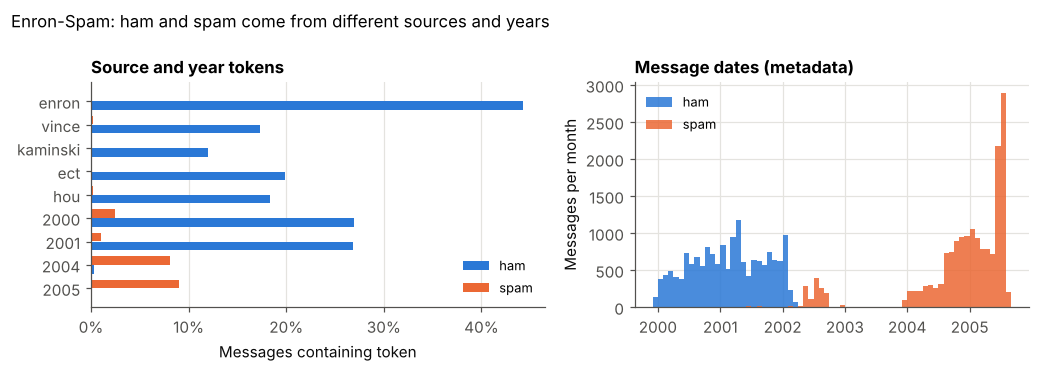

In [11]:
SOURCE_TOKENS = ["enron", "vince", "kaminski", "ect", "hou", "2000", "2001", "2004", "2005"]
en = data["Enron-Spam"]
rows = [{"token": t, "ham": en.tokens[en.spam == 0].map(lambda ts, t=t: t in ts).mean(),
         "spam": en.tokens[en.spam == 1].map(lambda ts, t=t: t in ts).mean()} for t in SOURCE_TOKENS]
src = pd.DataFrame(rows).set_index("token")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
y = np.arange(len(src))
ax.barh(y + 0.19, src.ham, 0.36, color=HAM, label="ham")
ax.barh(y - 0.19, src.spam, 0.36, color=SPAM, label="spam")
ax.set_yticks(y, src.index); ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Messages containing token"); ax.set_title("Source and year tokens")
ax.legend(loc="lower right", fontsize=8.5); ax.grid(axis="y", visible=False)

ax = axes[1]
d = raw["Enron-Spam"].dropna(subset=["date"])
months = pd.date_range(d.date.min().to_period("M").to_timestamp(), d.date.max(), freq="MS")
for cls, col, lab in ((0, HAM, "ham"), (1, SPAM, "spam")):
    ax.hist(d.date[d.spam == cls], bins=months, color=col, alpha=0.85, label=lab)
ax.set_title("Message dates (metadata)"); ax.set_ylabel("Messages per month")
ax.legend(fontsize=8.5)
fig.suptitle("Enron-Spam: ham and spam come from different sources and years", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()
print(src.round(3).to_string())
print("\nDate range by class:")
print(d.groupby("spam").date.agg(["min", "median", "max"]).rename(index={0: "ham", 1: "spam"}).to_string())

**Findings:** Enron-Spam's ham and spam come from different sources and different years. Ham is real Enron mail from December 1999 to March 2002. Spam was collected separately, mostly in 2004–2005 (median January 2005). Source tokens are almost perfectly one-sided: "enron" appears in 44% of ham and no spam, and "kaminski" in 12% of ham and no spam. Year tokens mirror the date gap: "2000" and "2001" each appear in about 27% of ham, while "2004" and "2005" each appear in 8–9% of spam. We will not use the date column, but these tokens stay in the text. Removing them would be an arbitrary, hand-picked filter, and the corpus is a standard benchmark as published. 

We will keep the text as is, but expect Enron to be an easier task with lower error than SMS. This source/time difference will just be a limitation when interpreting Enron results.


## 7. Top-n vocabularies

For each candidate n, we will keep the n highest-MI tokens and represent a message as a binary vector. Two things matter for our planned learning curves: how many of the n features a typical message activates, and how rare the last features added are.

       mean_active                          no_feature                       
corpus  Enron-Spam         SMS Spam         Enron-Spam        SMS Spam       
class          ham    spam      ham    spam        ham   spam      ham   spam
n                                                                            
16           4.332   1.096    0.976   3.595      0.127  0.288    0.359  0.023
32           7.303   2.584    1.078   5.086      0.023  0.111    0.337  0.012
64          11.302   4.868    1.567   7.286      0.011  0.052    0.244  0.004
128         16.719   8.558    2.076   9.327      0.004  0.023    0.192  0.000
256         23.624  14.991    3.148  11.848      0.004  0.010    0.110  0.000
512         33.125  24.423    3.986  13.181      0.002  0.005    0.066  0.000
1024        42.523  34.250    6.587  16.091      0.001  0.003    0.014  0.000
2048        56.873  47.830    9.792  18.545      0.001  0.002    0.004  0.000
4096        69.662  60.278      NaN     NaN      0.000  0.001   

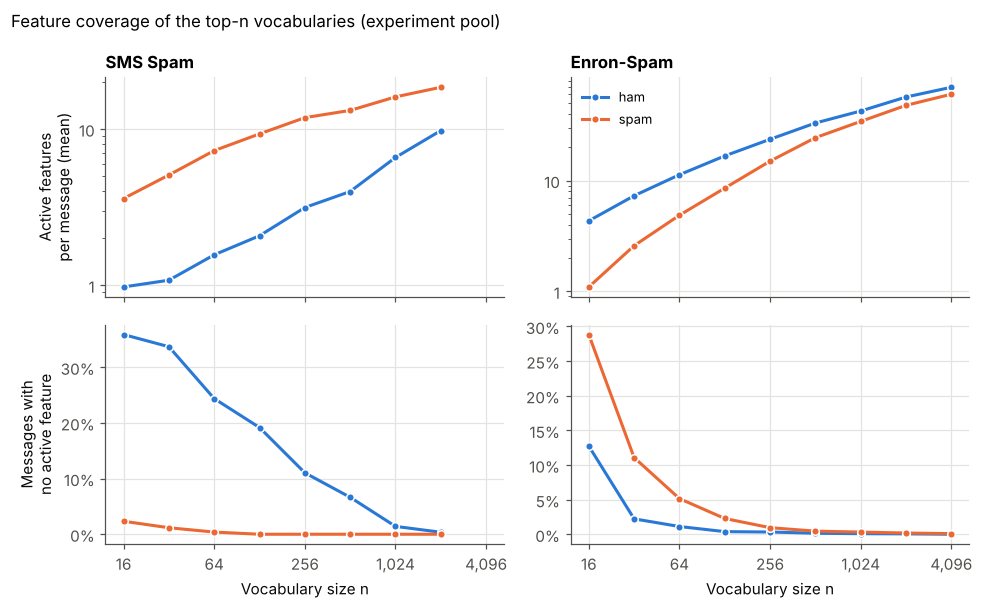

In [12]:
N_GRID = [16, 32, 64, 128, 256, 512, 1024, 2048, 4096]
cov_rows = []
for name, df in data.items():
    pool = df.iloc[pool_idx[name]]
    order = {t: i for i, t in enumerate(ranked[name].token)}
    ranks = pool.tokens.map(lambda ts: np.array(sorted({order[t] for t in ts if t in order}), dtype=int))
    for n in N_GRID:
        if n > len(order): continue
        active = ranks.map(lambda r, n=n: int(np.searchsorted(r, n)))
        for cls, lab in ((0, "ham"), (1, "spam")):
            a = active[pool.spam == cls]
            cov_rows.append({"corpus": name, "n": n, "class": lab, "mean_active": a.mean(), "no_feature": (a == 0).mean()})
cov = pd.DataFrame(cov_rows)

fig, axes = plt.subplots(2, 2, figsize=(9, 5.6), sharex=True)
for j, name in enumerate(CORPORA):
    c = cov[cov.corpus == name]
    for cls, col in (("ham", HAM), ("spam", SPAM)):
        cc = c[c["class"] == cls]
        axes[0, j].plot(cc.n, cc.mean_active, "-o", color=col, markersize=5, markeredgecolor="white", label=cls)
        axes[1, j].plot(cc.n, cc.no_feature, "-o", color=col, markersize=5, markeredgecolor="white", label=cls)
    axes[0, j].set_title(name)
    axes[0, j].set_yscale("log"); axes[0, j].yaxis.set_major_formatter(thousands)
    axes[1, j].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    axes[1, j].set_xscale("log", base=2); axes[1, j].xaxis.set_major_formatter(thousands)
    axes[1, j].set_xlabel("Vocabulary size n")
axes[0, 0].set_ylabel("Active features\nper message (mean)")
axes[1, 0].set_ylabel("Messages with\nno active feature")
axes[0, 1].legend(fontsize=8.5)
fig.suptitle("Feature coverage of the top-n vocabularies (experiment pool)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()
print(cov.pivot_table(index="n", columns=["corpus", "class"], values=["mean_active", "no_feature"]).round(3).to_string())

**Findings:** At small n, many messages contain none of the selected features. With n = 16, 36% of SMS ham and 29% of Enron spam have an all-zero feature vector. Each corpus's top features mostly describe its "marked" class (spam on SMS, ham on Enron), so the other class is largely recognized by absence. Coverage rises quickly with n: by n = 256 almost every message has at least one active feature. Even at the largest n, a message activates only a small fraction of the vocabulary (SMS spam about 19 of 2,048; Enron about 60–70 of 4,096). The feature vectors are very sparse, and a binary model at large n will see most features absent in most messages.


mean in-class rate (%) of the features ranked n/2 ... n:
corpus Enron-Spam        SMS Spam        
class         ham   spam      ham    spam
n                                        
16         24.749  5.196    3.860  19.042
32         18.568  9.300    0.638   9.314
64         12.497  7.138    1.530   6.876
128         8.464  5.765    0.795   3.189
256         5.395  5.026    0.838   1.970
512         3.711  3.684    0.328   0.521
1024        1.836  1.919    0.508   0.568
2048        1.401  1.326    0.313   0.240
4096        0.624  0.608      NaN     NaN


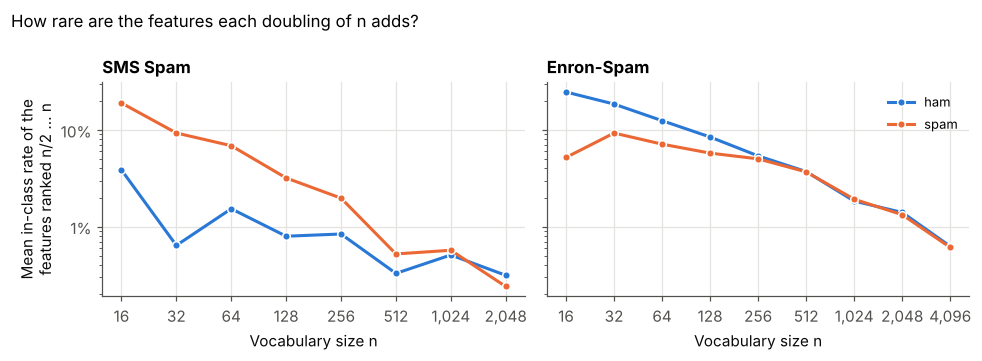

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), sharey=True)
rare_rows = []
for ax, name in zip(axes, CORPORA):
    df = data[name]
    pool = df.iloc[pool_idx[name]]
    top = ranked[name].token.head(min(4096, len(ranked[name]))).tolist()
    for cls, col, lab in ((0, HAM, "ham"), (1, SPAM, "spam")):
        sub = pool[pool.spam == cls]
        dfc = Counter(t for ts in sub.tokens for t in set(ts))
        rate = np.array([dfc[t] / len(sub) for t in top])
        # mean in-class rate of the tokens added between n/2 and n (the "newest" features at each n)
        ns = [n for n in N_GRID if n <= len(top)]
        med = [np.mean(rate[n // 2: n]) for n in ns]
        ax.plot(ns, med, "-o", color=col, markersize=5, markeredgecolor="white", label=lab)
        for n, m in zip(ns, med):
            rare_rows.append({"corpus": name, "class": lab, "n": n, "mean_rate": m})
    ax.set_xscale("log", base=2); ax.set_yscale("log")
    ax.xaxis.set_major_formatter(thousands)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _p: f"{v * 100:g}%"))
    ax.set_title(name); ax.set_xlabel("Vocabulary size n")
axes[0].set_ylabel("Mean in-class rate of the\nfeatures ranked n/2 ... n")
axes[1].legend(fontsize=8.5)
fig.suptitle("How rare are the features each doubling of n adds?", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()
rare = pd.DataFrame(rare_rows).pivot_table(index="n", columns=["corpus", "class"], values="mean_rate")
print("mean in-class rate (%) of the features ranked n/2 ... n:")
print((100 * rare).round(3).to_string())

**Findings:** Each doubling of n adds rarer features. The features ranked between n/2 and n appear on average in about 19% of SMS spam messages at n = 16, but only about 0.2–0.6% at n = 1,024–2,048. On Enron the rate falls from about 25% (ham) at n = 16 to about 0.6% at n = 4,096. Combine this with small training sets: at m = 64 an SMS training set holds about 8 spam messages, so a feature that appears in 0.5% of spam is expected in 8 × 0.005 = 0.04 of them, and is almost never observed. For the generative model, the estimates for these features will be set by its prior smoothing, not by data. There are thousands at large n, and naive Bayes adds up one term for each absent feature, so the choice of smoothing constant α could dominate its predictions on small samples.

For now, we will run naive Bayes with the paper's α = 1 as planned, and check whether its small-m behaviour at large n is driven by smoothing.

## 8. Dataset size (in relation to our planned (n, m) grid)

Ng & Jordan bound logistic regression's sample complexity by O(n). If the crossover needs on the order of n training examples, it is only observable where the largest training set m_max is well above n. m_max = pool size - test set (1,000 for SMS, 2,000 for Enron).

SMS Spam: pool 4,128, test 1,000, m_max 3,128, m_max/n at n=1024: 3.1, at largest feasible n=2048: 1.5
Enron-Spam: pool 24,110, test 2,000, m_max 22,110, m_max/n at n=1024: 21.6, at largest feasible n=4096: 5.4


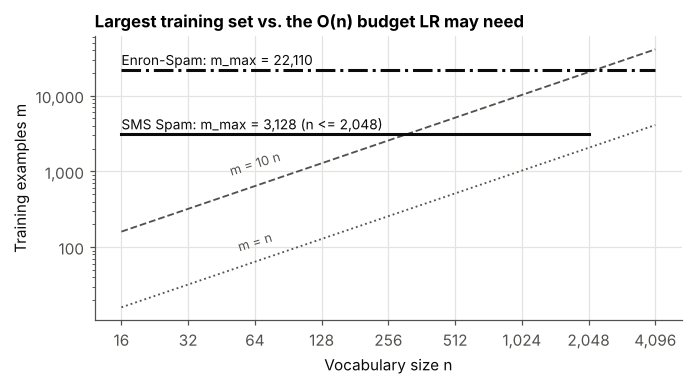

In [14]:
TEST_SIZE = {"SMS Spam": 1000, "Enron-Spam": 2000}
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ns = np.array(N_GRID)
ax.plot(ns, ns, color=MUTED, linewidth=1.2, linestyle=":")
ax.plot(ns, 10 * ns, color=MUTED, linewidth=1.2, linestyle="--")
ax.text(64, 64 * 1.25, "m = n", ha="center", va="bottom", fontsize=8.5, color=MUTED, rotation=17)
ax.text(64, 640 * 1.25, "m = 10 n", ha="center", va="bottom", fontsize=8.5, color=MUTED, rotation=17)
for name, style in zip(CORPORA, ("-", "-.")):
    m_max = len(pool_idx[name]) - TEST_SIZE[name]
    n_cap = len(ranked[name])
    valid = ns[ns <= n_cap]
    ax.plot(valid, np.full(len(valid), m_max), style, color=INK, linewidth=2)
    ax.text(valid[0], m_max * 1.15, f"{name}: m_max = {m_max:,}" + ("" if n_cap >= ns[-1] else f" (n <= {valid[-1]:,})"),
            fontsize=9, color=INK)
    print(f"{name}: pool {len(pool_idx[name]):,}, test {TEST_SIZE[name]:,}, m_max {m_max:,}, "
          f"m_max/n at n=1024: {m_max / 1024:.1f}, at largest feasible n={valid[-1]}: {m_max / valid[-1]:.1f}")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.xaxis.set_major_formatter(thousands); ax.yaxis.set_major_formatter(thousands)
ax.set_xlabel("Vocabulary size n"); ax.set_ylabel("Training examples m")
ax.set_title("Largest training set vs. the O(n) budget LR may need")
fig.tight_layout()
plt.show()

**Findings:** After setting aside the dev split and a test set, SMS leaves at most m_max = 3,128 training messages and Enron 22,110. The paper's bound says logistic regression may need on the order of n examples (a constant times n) to approach its best error. On SMS, m_max is only 3.1 times n at n = 1,024 and 1.5 times at n = 2,048. It falls below 10n beyond n of about 300, so for most of the SMS grid a crossover would have to happen with fewer than ten examples per feature. Enron's m_max stays above 10n up to n of about 2,200, and is still 5.4 times n at n = 4,096.

SMS alone may only show the large-m regime for small n. Where the crossover lies beyond m_max we can report only a lower bound (m* > 3,128). This is the main reason to analyse Enron alongside SMS, because it gives an order of magnitude more room in m on the same task.

## 9. Summary: decisions for the experiment pipeline

| Issue | EDA Analysis | Decision |
|---|---|---|
| Duplicates | 415 (SMS) and 3,578 (Enron) exact copies; spam duplicated ~2x more; no label conflicts | Drop copies: 5,159 SMS and 30,138 Enron messages remain |
| Class balance | SMS 12.4% spam, Enron 48.3% | Stratified splits with at least one example of each class |
| Tokenizer | Default pattern drops "i", "!", "£", "u", "2", "4" | `[a-z, 0-9]+\|[£$€!]`, lower-cased, binary presence |
| Vocabulary cap | SMS dev split has 3,362 distinct tokens | n = 16 ... 2,048 (SMS), 16 ... 4,096 (Enron), ranked by MI on a 20% dev split |
| Data per n | m_max = 3,128 (SMS) vs. 22,110 (Enron) | Use both databases; report censored crossovers as lower bounds |
| Rare features | Large-n features appear in < 1% of messages; at small m most are never seen | Watch whether NB's smoothing (α = 1) drives small-m results |
| Enron artifacts | Source tokens ("enron", "kaminski") and year tokens split the classes; ham 1999–2002, spam mostly 2004–2005 | Keep text unchanged and the date column unused|
